In [2]:
#import packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [12]:
df = pd.read_excel(r'C:\Users\Rosan\Downloads\82210-1.xlsx')
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 20 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Y       1826 non-null   int64  
 1   M       1826 non-null   int64  
 2   D       1826 non-null   int64  
 3   T       1826 non-null   float64
 4   TM      1826 non-null   float64
 5   Tm      1826 non-null   float64
 6   SLP     1826 non-null   object 
 7   STP     1826 non-null   object 
 8   H       1826 non-null   object 
 9   PP      1826 non-null   object 
 10  VV      1826 non-null   float64
 11  V       1826 non-null   float64
 12  VM      1826 non-null   object 
 13  VG      1826 non-null   object 
 14  FG      1826 non-null   int64  
 15  RA      1826 non-null   int64  
 16  SN      1826 non-null   int64  
 17  GR      1826 non-null   int64  
 18  TS      1826 non-null   int64  
 19  TR      1826 non-null   int64  
dtypes: float64(5), int64(9), object(6)
memory usage: 285.4+ KB
None
      Y  M

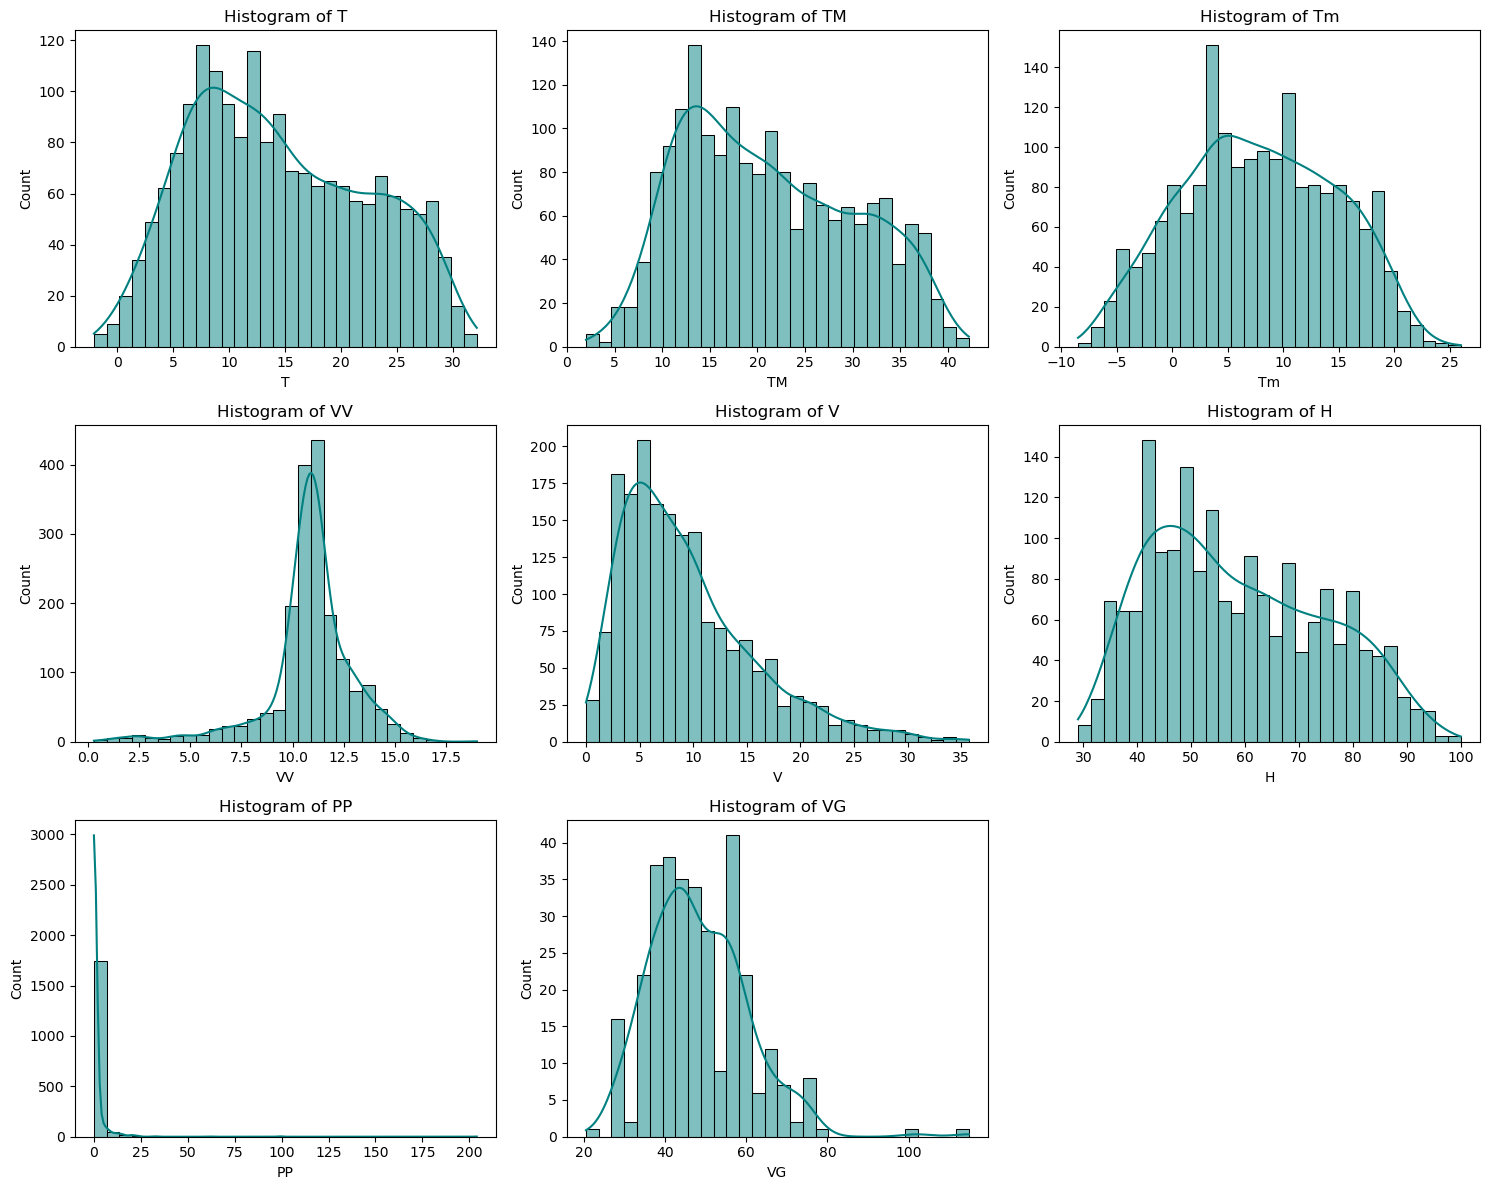

In [19]:
# Clean non-numeric character columns
for col in ['SLP', 'STP', 'H', 'PP', 'VM', 'VG']:
  df[col] = pd.to_numeric(df[col], errors='coerce')

num_cols = ['T', 'TM', 'Tm', 'VV', 'V', 'H', 'PP', 'VG']

# 2. Univariate Histograms
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(num_cols):
  sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='teal', bins=30)
  axes[i].set_title(f'Histogram of {col}')
for j in range(len(num_cols), len(axes)):
  fig.delaxes(axes[j])
plt.tight_layout()
plt.show()
#plt.savefig('../outputs/histograms.png')
#plt.close()

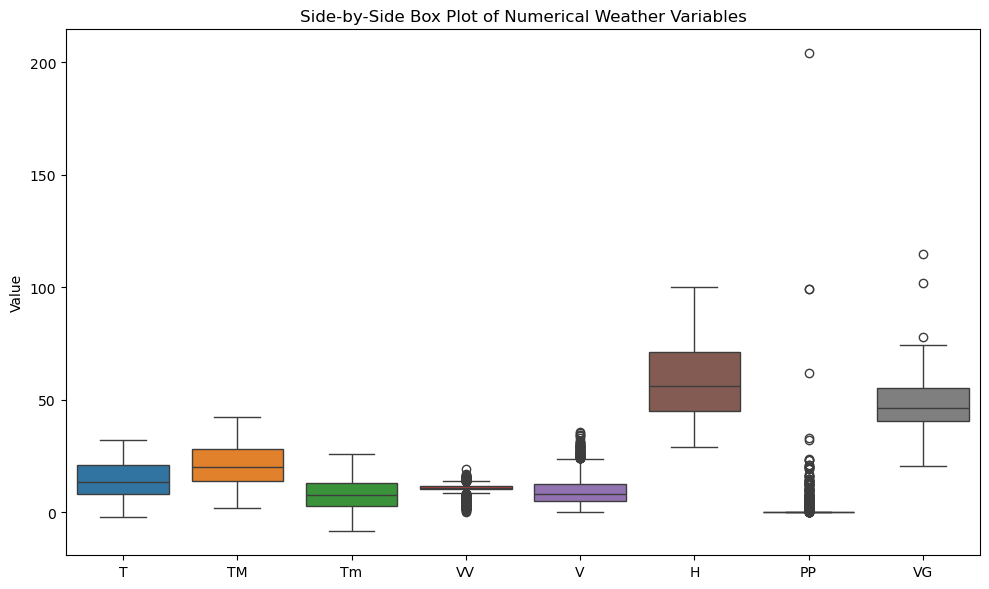

In [22]:
# Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[num_cols])
plt.title('Side-by-Side Box Plot of Numerical Weather Variables')
plt.ylabel('Value')
plt.tight_layout()
plt.show()

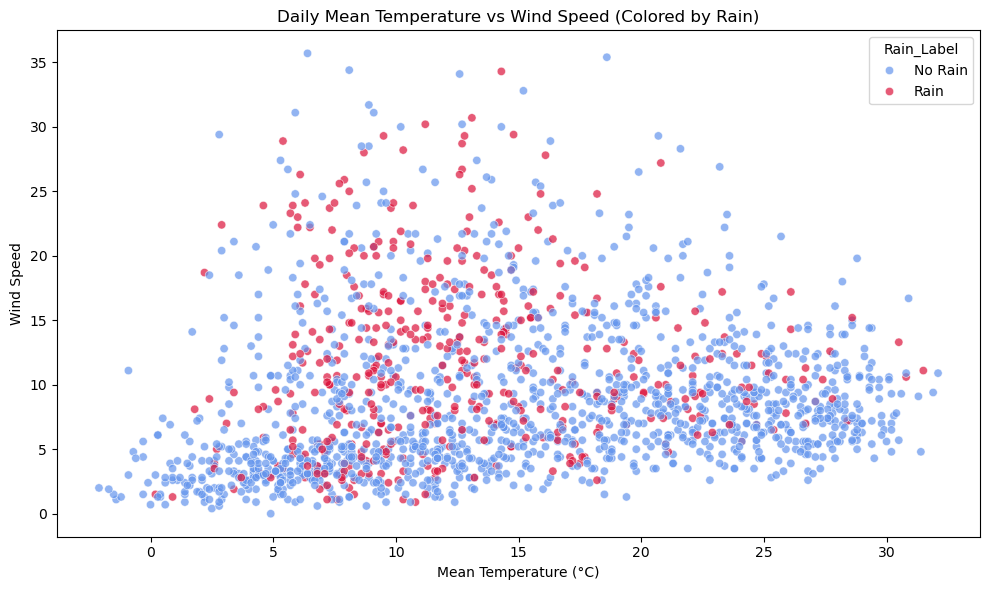

In [24]:
# Categorical vs Numerical with Color (Hue)
df['Rain_Label'] = df['RA'].map({0: 'No Rain', 1: 'Rain'})
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='T',
    y='V',
    hue='Rain_Label',
    palette={'No Rain': 'cornflowerblue', 'Rain': 'crimson'},
    alpha=0.7,
)
plt.title('Daily Mean Temperature vs Wind Speed (Colored by Rain)')
plt.xlabel('Mean Temperature (°C)')
plt.ylabel('Wind Speed')
plt.tight_layout()